## Setup

In [ ]:
import importlib
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))


from evaluation import rmse_from_predictions, mae_from_predictions
from als import als_model_numba, als_model_sparse, predict_pairs_numba_kernel
from sgd import sgd_numba

## Load processed training data

In [3]:
DATASET_NAME = "ml-latest"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / DATASET_NAME

train_df = pd.read_csv(PROCESSED_DIR / "train_ratings.csv")
user_map = pd.read_csv(PROCESSED_DIR / "user_map.csv")
movie_map = pd.read_csv(PROCESSED_DIR / "movie_map.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test_ratings.csv")

n_users = len(user_map)
n_movies = len(movie_map)

print("Train shape:", train_df.shape)
print("Number of users:", n_users)
print("Number of movies:", n_movies)

Train shape: (27065729, 6)
Number of users: 330975
Number of movies: 83239


In [4]:
user_idx = train_df["user_idx"].to_numpy(dtype=np.int64)
movie_idx = train_df["movie_idx"].to_numpy(dtype=np.int64)
ratings = train_df["rating"].to_numpy(dtype=np.float64)

print(user_idx.flags.c_contiguous)
print(movie_idx.flags.c_contiguous)
print(ratings.flags.c_contiguous)

True
True
True


## Train-validation split

In [5]:
train_fit_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    shuffle=True,
)

print("Train fit shape:", train_fit_df.shape)
print("Validation shape:", val_df.shape)

Train fit shape: (21652583, 6)
Validation shape: (5413146, 6)


## Baseline Model


In [11]:
from evaluation import mae_from_predictions

global_mean = train_df["rating"].mean()

train_baseline_preds = np.full(
    shape=len(train_df),
    fill_value=global_mean
)

test_baseline_preds = np.full(
    shape=len(test_df),
    fill_value=global_mean
)

baseline_train_rmse = rmse_from_predictions(train_df["rating"].values, train_baseline_preds)
baseline_train_mae = mae_from_predictions(train_df["rating"].values, train_baseline_preds)

baseline_test_rmse = rmse_from_predictions(test_df["rating"].values, test_baseline_preds)
baseline_test_mae = mae_from_predictions(test_df["rating"].values, test_baseline_preds)

print("Global mean:", global_mean)

print("Baseline train RMSE:", baseline_train_rmse)
print("Baseline train MAE:", baseline_train_mae)

print("Baseline test RMSE:", baseline_test_rmse)
print("Baseline test MAE:", baseline_test_mae)

Global mean: 3.5425329574533166
Baseline train RMSE: 1.0638921636833796
Baseline train MAE: 0.8428200505887136
Baseline test RMSE: 1.0642243146026569
Baseline test MAE: 0.8431218080817922


## ALS

### Validation RMSE

In [7]:
val_user_idx = val_df["user_idx"].to_numpy(dtype=np.int64)
val_movie_idx = val_df["movie_idx"].to_numpy(dtype=np.int64)
val_ratings = val_df["rating"].to_numpy(dtype=np.float64)

def als_validation_metrics(U, V, global_mean):
    predictions = predict_pairs_numba_kernel(
        U,
        V,
        val_user_idx,
        val_movie_idx,
        global_mean,
    )
    predictions = np.clip(predictions, 0.5, 5.0)

    return {
        "val_rmse": rmse_from_predictions(val_ratings, predictions),
    }

### Sparse and Numba runtime comparison

In [9]:
benchmark_rank = 10
benchmark_reg = 10.0
benchmark_n_iter = 5

warmup_df = train_fit_df.iloc[:1_000]

for parallel in (False, True):
    warmup_result = als_model_numba(
        warmup_df,
        n_users=n_users,
        n_movies=n_movies,
        rank=benchmark_rank,
        reg=benchmark_reg,
        n_iter=1,
        random_state=42,
        parallel=parallel,
        objective_tol=None,
    )
    del warmup_result

benchmark_configs = [
    ("Sparse NumPy", als_model_sparse, {}),
    ("Numba sequential", als_model_numba, {"parallel": False}),
    ("Numba parallel", als_model_numba, {"parallel": True}),
]

benchmark_rows = []

for name, model, extra_kwargs in benchmark_configs:
    start = perf_counter()
    U_benchmark, V_benchmark, _, history_benchmark = model(
        train_fit_df,
        n_users=n_users,
        n_movies=n_movies,
        rank=benchmark_rank,
        reg=benchmark_reg,
        n_iter=benchmark_n_iter,
        random_state=42,
        objective_tol=None,
        **extra_kwargs,
    )
    elapsed = perf_counter() - start
    final_row = history_benchmark.iloc[-1]

    benchmark_rows.append({
        "implementation": name,
        "seconds_per_sweep": elapsed / benchmark_n_iter,
        "objective": final_row["objective"],
        "train_rmse": final_row["train_rmse"],
    })

    del U_benchmark, V_benchmark, history_benchmark

als_benchmark_df = pd.DataFrame(benchmark_rows)
sparse_seconds = als_benchmark_df.loc[
    als_benchmark_df["implementation"] == "Sparse NumPy",
    "seconds_per_sweep",
].iloc[0]
als_benchmark_df["speedup_vs_sparse"] = (
    sparse_seconds / als_benchmark_df["seconds_per_sweep"]
)

display(als_benchmark_df)

,implementation,seconds_per_sweep,objective,train_rmse,speedup_vs_sparse
0,Sparse NumPy,16.465140,6.553852e+06,0.731818,1.000000
1,Numba sequential,7.128118,6.553852e+06,0.731818,2.309886
2,Numba parallel,5.394708,6.553852e+06,0.731818,3.052091


### Hyperparameter grid

In [5]:
rank_values = [2, 3, 5, 10]
reg_values = [0.1, 1.0, 5.0, 10.0]
max_iter = 30
objective_tol = 1e-5
min_iter = 5
patience = 3

all_histories = []

for rank in rank_values:
    for reg in reg_values:
        print(f"Training ALS with rank={rank}, reg={reg}")

        _, _, _, history_df = als_model_numba(
            train_fit_df,
            n_users=n_users,
            n_movies=n_movies,
            rank=rank,
            reg=reg,
            n_iter=max_iter,
            random_state=42,
            metrics_fn=als_validation_metrics,
            parallel=True,
            min_iter=min_iter,
            objective_tol=objective_tol,
            patience=patience,
        )

        all_histories.append(history_df)

als_tuning_results_df = pd.concat(all_histories, ignore_index=True)

display(
    als_tuning_results_df
    .sort_values("val_rmse")
    .head(10)
)

Training ALS with rank=2, reg=0.1


Training ALS with rank=2, reg=1.0
Training ALS with rank=2, reg=5.0
Training ALS with rank=2, reg=10.0
Training ALS with rank=3, reg=0.1
Training ALS with rank=3, reg=1.0
Training ALS with rank=3, reg=5.0
Training ALS with rank=3, reg=10.0
Training ALS with rank=5, reg=0.1
Training ALS with rank=5, reg=1.0
Training ALS with rank=5, reg=5.0
Training ALS with rank=5, reg=10.0
Training ALS with rank=10, reg=0.1
Training ALS with rank=10, reg=1.0
Training ALS with rank=10, reg=5.0
Training ALS with rank=10, reg=10.0


,iteration,rank,reg,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse
478,30,10,10.0,6.317481e+06,0.716814,0.715974,0.000023,0.805937
477,29,10,10.0,6.317626e+06,0.716822,0.715981,0.000027,0.805958
476,28,10,10.0,6.317794e+06,0.716831,0.715990,0.000031,0.805983
475,27,10,10.0,6.317992e+06,0.716842,0.716001,0.000037,0.806010
474,26,10,10.0,6.318224e+06,0.716856,0.716015,0.000044,0.806041
473,25,10,10.0,6.318500e+06,0.716873,0.716032,0.000052,0.806077
472,24,10,10.0,6.318832e+06,0.716894,0.716053,0.000063,0.806119
471,23,10,10.0,6.319232e+06,0.716920,0.716079,0.000077,0.806168
470,22,10,10.0,6.319722e+06,0.716952,0.716112,0.000096,0.806225
469,21,10,10.0,6.320327e+06,0.716993,0.716153,0.000119,0.806293


In [7]:
refined_rank_values = [8, 10, 12, 15]
refined_reg_values = [5.0, 10.0, 20.0]
max_iter = 40
objective_tol = 1e-5
min_iter = 5
patience = 3

all_histories = []

for rank in refined_rank_values:
    for reg in refined_reg_values:
        print(f"Training ALS with rank={rank}, reg={reg}")

        _, _, _, history_df = als_model_numba(
            train_fit_df,
            n_users=n_users,
            n_movies=n_movies,
            rank=rank,
            reg=reg,
            n_iter=max_iter,
            random_state=42,
            metrics_fn=als_validation_metrics,
            parallel=True,
            min_iter=min_iter,
            objective_tol=objective_tol,
            patience=patience,
        )

        all_histories.append(history_df)

als_tuning_results_df = pd.concat(all_histories, ignore_index=True)

display(
    als_tuning_results_df
    .sort_values("val_rmse")
    .head(10)
)

Training ALS with rank=8, reg=5.0
Training ALS with rank=8, reg=10.0
Training ALS with rank=8, reg=20.0
Training ALS with rank=10, reg=5.0
Training ALS with rank=10, reg=10.0
Training ALS with rank=10, reg=20.0
Training ALS with rank=12, reg=5.0
Training ALS with rank=12, reg=10.0
Training ALS with rank=12, reg=20.0
Training ALS with rank=15, reg=5.0
Training ALS with rank=15, reg=10.0
Training ALS with rank=15, reg=20.0


,iteration,rank,reg,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse
427,40,15,10.0,5.914639e+06,0.683318,0.682245,0.000040,0.803865
426,39,15,10.0,5.914874e+06,0.683342,0.682270,0.000044,0.803896
425,38,15,10.0,5.915134e+06,0.683368,0.682296,0.000048,0.803929
424,37,15,10.0,5.915420e+06,0.683396,0.682325,0.000053,0.803966
423,36,15,10.0,5.915736e+06,0.683427,0.682357,0.000059,0.804006
422,35,15,10.0,5.916084e+06,0.683460,0.682390,0.000065,0.804050
421,34,15,10.0,5.916470e+06,0.683495,0.682427,0.000072,0.804099
420,33,15,10.0,5.916896e+06,0.683534,0.682467,0.000080,0.804152
419,32,15,10.0,5.917367e+06,0.683577,0.682510,0.000088,0.804211
310,40,12,10.0,6.137040e+06,0.702040,0.701075,0.000017,0.804212


In [6]:
refined_rank_values = [15, 18, 20]
refined_reg_values = [10.0]
max_iter = 60
objective_tol = 1e-5
min_iter = 5
patience = 3

all_histories = []

for rank in refined_rank_values:
    for reg in refined_reg_values:
        print(f"Training ALS with rank={rank}, reg={reg}")

        _, _, _, history_df = als_model_numba(
            train_fit_df,
            n_users=n_users,
            n_movies=n_movies,
            rank=rank,
            reg=reg,
            n_iter=max_iter,
            random_state=42,
            metrics_fn=als_validation_metrics,
            parallel=True,
            min_iter=min_iter,
            objective_tol=objective_tol,
            patience=patience,
        )

        all_histories.append(history_df)

als_tuning_results_df = pd.concat(all_histories, ignore_index=True)

display(
    als_tuning_results_df
    .sort_values("val_rmse")
    .head(10)
)

Training ALS with rank=15, reg=10.0
Training ALS with rank=18, reg=10.0
Training ALS with rank=20, reg=10.0


,iteration,rank,reg,objective,train_rmse_raw,train_rmse,relative_objective_decrease,val_rmse
56,57,15,10.0,5.912738e+06,0.683097,0.682016,0.000008,0.803626
55,56,15,10.0,5.912788e+06,0.683104,0.682023,0.000009,0.803631
54,55,15,10.0,5.912842e+06,0.683111,0.682031,0.000010,0.803638
53,54,15,10.0,5.912901e+06,0.683119,0.682039,0.000011,0.803645
52,53,15,10.0,5.912965e+06,0.683127,0.682048,0.000012,0.803652
51,52,15,10.0,5.913035e+06,0.683136,0.682057,0.000013,0.803661
50,51,15,10.0,5.913112e+06,0.683146,0.682068,0.000014,0.803670
49,50,15,10.0,5.913196e+06,0.683157,0.682078,0.000015,0.803680
48,49,15,10.0,5.913287e+06,0.683168,0.682090,0.000017,0.803692
47,48,15,10.0,5.913388e+06,0.683180,0.682103,0.000019,0.803705


### Select rank, regularization and retained sweep

In [ ]:
best_als_row = als_tuning_results_df.loc[
    als_tuning_results_df["val_rmse"].idxmin()
]

best_als_rank = int(best_als_row["rank"])
best_als_reg = float(best_als_row["reg"])
best_als_n_iter = int(best_als_row["iteration"])
best_als_val_rmse = float(best_als_row["val_rmse"])

best_als_history = (
    als_tuning_results_df
    .loc[
        (als_tuning_results_df["rank"] == best_als_rank)
        & (als_tuning_results_df["reg"] == best_als_reg)
    ]
    .sort_values("iteration")
)

print("Best ALS rank:", best_als_rank)
print("Best ALS reg:", best_als_reg)
print("Best ALS n_iter:", best_als_n_iter)
print("Best validation RMSE:", best_als_val_rmse)

Best ALS rank: 15
Best ALS reg: 10.0
Best ALS n_iter: 57
Best validation RMSE: 0.8036255964423781


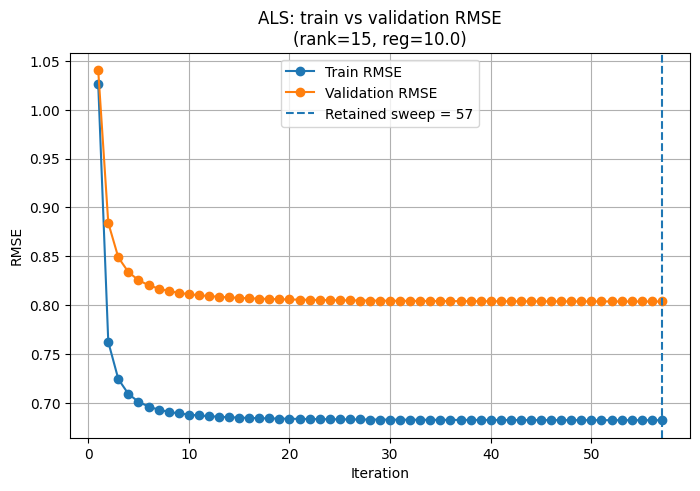

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    best_als_history["iteration"],
    best_als_history["train_rmse"],
    marker="o",
    label="Train RMSE",
)
plt.plot(
    best_als_history["iteration"],
    best_als_history["val_rmse"],
    marker="o",
    label="Validation RMSE",
)
plt.axvline(
    best_als_n_iter,
    linestyle="--",
    label=f"Retained sweep = {best_als_n_iter}",
)
plt.xlabel("Iteration")
plt.ylabel("RMSE")
plt.title(
    f"ALS: train vs validation RMSE\n"
    f"(rank={best_als_rank}, reg={best_als_reg})"
)
plt.legend()
plt.grid(True)
plt.show()

### Retrain on the full training set

In [8]:
best_als_rank = 15
best_als_reg = 10
best_als_n_iter = 57

In [9]:
U_als, V_als, als_global_mean, als_history = als_model_numba(
    train_df,
    n_users=n_users,
    n_movies=n_movies,
    rank=best_als_rank,
    reg=best_als_reg,
    n_iter=best_als_n_iter,
    random_state=42,
    parallel=True,
    objective_tol=None,
)

test_df = pd.read_csv(PROCESSED_DIR / "test_ratings.csv")
test_predictions = predict_pairs_numba_kernel(
    U_als,
    V_als,
    test_df["user_idx"].to_numpy(dtype=np.int64),
    test_df["movie_idx"].to_numpy(dtype=np.int64),
    als_global_mean,
)
test_predictions = np.clip(test_predictions, 0.5, 5.0)
test_ratings = test_df["rating"].to_numpy(dtype=np.float64)
als_test_rmse = rmse_from_predictions(test_ratings, test_predictions)
als_test_mae = mae_from_predictions(test_ratings, test_predictions)

print("Final ALS rank:", best_als_rank)
print("Final ALS reg:", best_als_reg)
print("Final ALS n_iter:", best_als_n_iter)
print("ALS test RMSE:", als_test_rmse)
print("ALS test MAE:", als_test_mae)

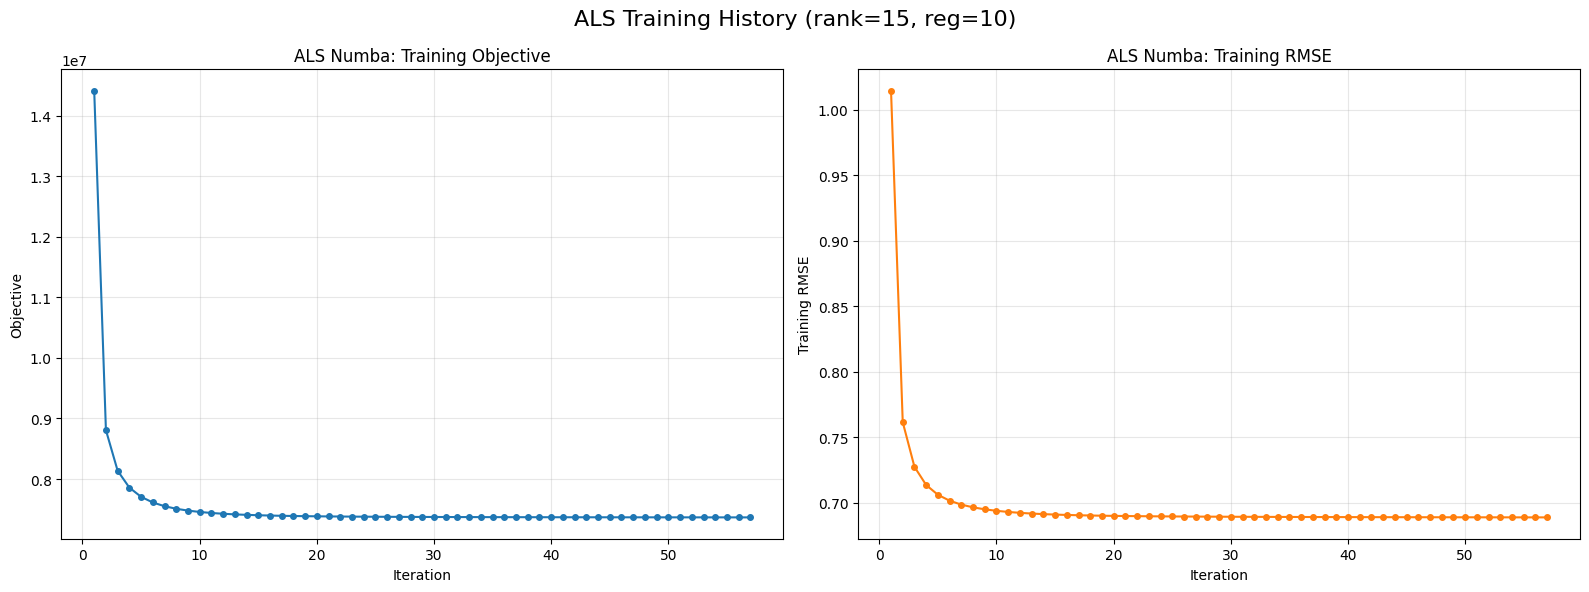

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fig.suptitle(
    "ALS Training History "
    f"(rank={best_als_rank}, reg={best_als_reg})",
    fontsize=16,
)

axes[0].plot(
    als_history["iteration"],
    als_history["objective"],
    marker="o",
    markersize=4,
)

axes[0].set_title("ALS Numba: Training Objective")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Objective")
axes[0].grid(alpha=0.3)

axes[1].plot(
    als_history["iteration"],
    als_history["train_rmse"],
    marker="o",
    markersize=4,
    color="tab:orange",
)

axes[1].set_title("ALS Numba: Training RMSE")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Training RMSE")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

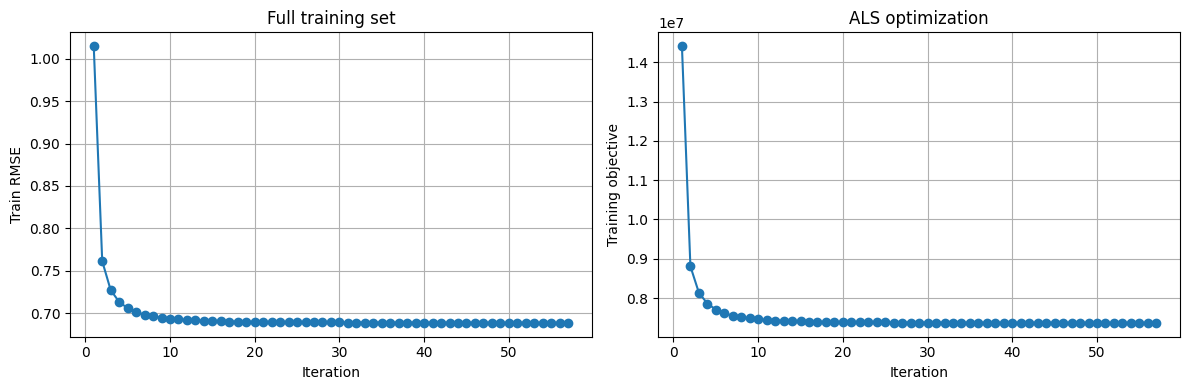

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    als_history["iteration"],
    als_history["train_rmse"],
    marker="o",
)
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Train RMSE")
axes[0].set_title("Full training set")
axes[0].grid(True)

axes[1].plot(
    als_history["iteration"],
    als_history["objective"],
    marker="o",
)
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Training objective")
axes[1].set_title("ALS optimization")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## SGD

### Parameter tuning

In [15]:
val_user_idx = val_df["user_idx"].to_numpy(dtype=np.int64)
val_movie_idx = val_df["movie_idx"].to_numpy(dtype=np.int64)
val_ratings = val_df["rating"].to_numpy(dtype=np.float64)


def sgd_validation_metrics(U, V, global_mean):
    predictions = predict_pairs_numba_kernel(
        U,
        V,
        val_user_idx,
        val_movie_idx,
        global_mean,
    )

    predictions = np.clip(predictions, 0.5, 5.0)

    return {
        "val_rmse": rmse_from_predictions(
            val_ratings,
            predictions,
        ),
    }

In [17]:
sgd_rank_values = [20, 50]
sgd_eta_values = [0.01, 0.015]
sgd_reg_values = [5.0, 10.0]
sgd_init_scale_values = [0.003]

max_iter = 10

sgd_histories = []

total_configs = (
    len(sgd_rank_values)
    * len(sgd_eta_values)
    * len(sgd_reg_values)
    * len(sgd_init_scale_values)
)

config_number = 0
search_start = perf_counter()

for rank in sgd_rank_values:
    for eta in sgd_eta_values:
        for reg in sgd_reg_values:
            for init_scale in sgd_init_scale_values:
                config_number += 1
                config_start = perf_counter()

                print(
                    f"[{config_number}/{total_configs}] "
                    f"rank={rank}, eta={eta}, reg={reg}, "
                    f"init_scale={init_scale}"
                )

                U_tmp, V_tmp, _, history_df = sgd_numba(
                    train_fit_df,
                    n_users=n_users,
                    n_movies=n_movies,
                    rank=rank,
                    eta=eta,
                    reg=reg,
                    n_iter=max_iter,
                    init_scale=init_scale,
                    random_state=42,
                    metrics_fn=sgd_validation_metrics,
                )

                sgd_histories.append(history_df)

                config_minutes = (
                    perf_counter() - config_start
                ) / 60

                total_minutes = (
                    perf_counter() - search_start
                ) / 60

                print(
                    f"Finished in {config_minutes:.2f} min; "
                    f"total time: {total_minutes:.2f} min\n"
                )

                del U_tmp, V_tmp, history_df

sgd_tuning_results_df = pd.concat(
    sgd_histories,
    ignore_index=True,
)

[1/8] rank=20, eta=0.01, reg=5.0, init_scale=0.003
Finished in 1.50 min; total time: 1.50 min

[2/8] rank=20, eta=0.01, reg=10.0, init_scale=0.003
Finished in 1.47 min; total time: 2.97 min

[3/8] rank=20, eta=0.015, reg=5.0, init_scale=0.003
Finished in 1.46 min; total time: 4.43 min

[4/8] rank=20, eta=0.015, reg=10.0, init_scale=0.003
Finished in 1.43 min; total time: 5.86 min

[5/8] rank=50, eta=0.01, reg=5.0, init_scale=0.003
Finished in 2.16 min; total time: 8.02 min

[6/8] rank=50, eta=0.01, reg=10.0, init_scale=0.003
Finished in 2.20 min; total time: 10.22 min

[7/8] rank=50, eta=0.015, reg=5.0, init_scale=0.003
Finished in 2.22 min; total time: 12.44 min

[8/8] rank=50, eta=0.015, reg=10.0, init_scale=0.003
Finished in 2.12 min; total time: 14.56 min



In [18]:
config_columns = ["rank", "eta", "reg", "init_scale"]

sgd_best_by_config = (
    sgd_tuning_results_df.loc[
        sgd_tuning_results_df
        .groupby(config_columns)["val_rmse"]
        .idxmin()
    ]
    .sort_values("val_rmse")
)

display(sgd_best_by_config.head(15))

,iteration,steps,rank,eta,reg,init_scale,objective,average_objective,train_rmse_raw,train_rmse,val_rmse
9,10,216525830,20,0.010,5.0,0.003,5.778597e+06,0.266878,0.701555,0.699960,0.811643
19,10,216525830,20,0.010,10.0,0.003,6.230630e+06,0.287755,0.710679,0.709220,0.812654
29,10,216525830,20,0.015,5.0,0.003,5.769123e+06,0.266440,0.693151,0.691395,0.812934
39,10,216525830,20,0.015,10.0,0.003,6.292921e+06,0.290631,0.705914,0.704289,0.814109
45,6,129915498,50,0.010,5.0,0.003,5.633792e+06,0.260190,0.697607,0.696106,0.815470
55,6,129915498,50,0.010,10.0,0.003,6.068938e+06,0.280287,0.707342,0.706095,0.815501
63,4,86610332,50,0.015,5.0,0.003,5.818932e+06,0.268741,0.708657,0.707129,0.819245
73,4,86610332,50,0.015,10.0,0.003,6.259851e+06,0.289104,0.717976,0.716681,0.819613


In [19]:
refined_rank_values = [10, 15, 20]
refined_eta_values = [0.008, 0.01, 0.012]
refined_reg_values = [2.5, 5.0]
refined_init_scale_values = [0.003]

max_iter = 10

sgd_refined_histories = []

total_configs = (
    len(refined_rank_values)
    * len(refined_eta_values)
    * len(refined_reg_values)
    * len(refined_init_scale_values)
)

config_number = 0
search_start = perf_counter()

for rank in refined_rank_values:
    for eta in refined_eta_values:
        for reg in refined_reg_values:
            for init_scale in refined_init_scale_values:
                config_number += 1
                config_start = perf_counter()

                print(
                    f"[{config_number}/{total_configs}] "
                    f"rank={rank}, eta={eta}, reg={reg}, "
                    f"init_scale={init_scale}"
                )

                U_tmp, V_tmp, _, history_df = sgd_numba(
                    train_fit_df,
                    n_users=n_users,
                    n_movies=n_movies,
                    rank=rank,
                    eta=eta,
                    reg=reg,
                    n_iter=max_iter,
                    init_scale=init_scale,
                    random_state=42,
                    metrics_fn=sgd_validation_metrics,
                )

                sgd_refined_histories.append(history_df)

                config_minutes = (
                    perf_counter() - config_start
                ) / 60

                total_minutes = (
                    perf_counter() - search_start
                ) / 60

                print(
                    f"Finished in {config_minutes:.2f} min; "
                    f"total time: {total_minutes:.2f} min\n"
                )

                del U_tmp, V_tmp, history_df

sgd_refined_results_df = pd.concat(
    sgd_refined_histories,
    ignore_index=True,
)

[1/18] rank=10, eta=0.008, reg=2.5, init_scale=0.003
Finished in 1.14 min; total time: 1.14 min

[2/18] rank=10, eta=0.008, reg=5.0, init_scale=0.003
Finished in 1.07 min; total time: 2.21 min

[3/18] rank=10, eta=0.01, reg=2.5, init_scale=0.003
Finished in 1.24 min; total time: 3.45 min

[4/18] rank=10, eta=0.01, reg=5.0, init_scale=0.003
Finished in 1.05 min; total time: 4.50 min

[5/18] rank=10, eta=0.012, reg=2.5, init_scale=0.003
Finished in 1.05 min; total time: 5.55 min

[6/18] rank=10, eta=0.012, reg=5.0, init_scale=0.003
Finished in 1.07 min; total time: 6.62 min

[7/18] rank=15, eta=0.008, reg=2.5, init_scale=0.003
Finished in 1.40 min; total time: 8.01 min

[8/18] rank=15, eta=0.008, reg=5.0, init_scale=0.003
Finished in 1.25 min; total time: 9.26 min

[9/18] rank=15, eta=0.01, reg=2.5, init_scale=0.003
Finished in 1.37 min; total time: 10.63 min

[10/18] rank=15, eta=0.01, reg=5.0, init_scale=0.003
Finished in 1.38 min; total time: 12.01 min

[11/18] rank=15, eta=0.012, reg

In [20]:
config_columns = ["rank", "eta", "reg", "init_scale"]

sgd_refined_best_by_config = (
    sgd_refined_results_df.loc[
        sgd_refined_results_df
        .groupby(config_columns)["val_rmse"]
        .idxmin()
    ]
    .sort_values("val_rmse")
)

display(sgd_refined_best_by_config.head(15))

,iteration,steps,rank,eta,reg,init_scale,objective,average_objective,train_rmse_raw,train_rmse,val_rmse
109,10,216525830,15,0.012,2.5,0.003,5.741028e+06,0.265143,0.711290,0.709850,0.810908
119,10,216525830,15,0.012,5.0,0.003,6.017604e+06,0.277916,0.715937,0.714550,0.811379
89,10,216525830,15,0.010,2.5,0.003,5.787393e+06,0.267284,0.716360,0.714972,0.811512
149,10,216525830,20,0.010,2.5,0.003,5.509317e+06,0.254442,0.697131,0.695462,0.811513
159,10,216525830,20,0.010,5.0,0.003,5.778597e+06,0.266878,0.701555,0.699960,0.811643
169,10,216525830,20,0.012,2.5,0.003,5.456002e+06,0.251979,0.691233,0.689490,0.811709
179,10,216525830,20,0.012,5.0,0.003,5.754689e+06,0.265774,0.696465,0.694792,0.811817
99,10,216525830,15,0.010,5.0,0.003,6.037615e+06,0.278840,0.720299,0.718965,0.811961
129,10,216525830,20,0.008,2.5,0.003,5.626627e+06,0.259859,0.707458,0.705917,0.812337
139,10,216525830,20,0.008,5.0,0.003,5.860908e+06,0.270679,0.711117,0.709652,0.812514


In [ ]:
best_sgd_rank = 15
best_sgd_eta = 0.012
best_sgd_reg = 2.5
best_sgd_init_scale = 0.003

U_tmp, V_tmp, _, sgd_finalist_history = sgd_numba(
    train_fit_df,
    n_users=n_users,
    n_movies=n_movies,
    rank=best_sgd_rank,
    eta=best_sgd_eta,
    reg=best_sgd_reg,
    n_iter=30,
    init_scale=best_sgd_init_scale,
    random_state=42,
    metrics_fn=sgd_validation_metrics,
)

best_iteration_row = sgd_finalist_history.loc[
    sgd_finalist_history["val_rmse"].idxmin()
]

best_sgd_n_iter = int(best_iteration_row["iteration"])

iteration            1.400000e+01
steps                3.031362e+08
rank                 1.500000e+01
eta                  1.200000e-02
reg                  2.500000e+00
init_scale           3.000000e-03
objective            5.617086e+06
average_objective    2.594188e-01
train_rmse_raw       6.999265e-01
train_rmse           6.984065e-01
val_rmse             8.103560e-01
Name: 13, dtype: float64

Best SGD parameters:
rank       = 15
eta        = 0.012
reg        = 2.5
init_scale = 0.003
n_iter     = 14
val_rmse   = 0.810356


In [23]:
display(best_iteration_row)

print("Best SGD parameters:")
print(f"rank       = {best_sgd_rank}")
print(f"eta        = {best_sgd_eta}")
print(f"reg        = {best_sgd_reg}")
print(f"init_scale = {best_sgd_init_scale}")
print(f"n_iter     = {best_sgd_n_iter}")
print(f"val_rmse   = {best_iteration_row['val_rmse']}")


iteration            1.400000e+01
steps                3.031362e+08
rank                 1.500000e+01
eta                  1.200000e-02
reg                  2.500000e+00
init_scale           3.000000e-03
objective            5.617086e+06
average_objective    2.594188e-01
train_rmse_raw       6.999265e-01
train_rmse           6.984065e-01
val_rmse             8.103560e-01
Name: 13, dtype: float64

Best SGD parameters:
rank       = 15
eta        = 0.012
reg        = 2.5
init_scale = 0.003
n_iter     = 14
val_rmse   = 0.8103560393320101


### Full training and test data set

In [9]:
best_sgd_rank = 15
best_sgd_eta = 0.012
best_sgd_reg = 2.5
best_sgd_init_scale = 0.003
best_sgd_n_iter = 14

U_sgd, V_sgd, sgd_global_mean, sgd_history = sgd_numba(
    train_df,
    n_users=n_users,
    n_movies=n_movies,
    rank=best_sgd_rank,
    eta=best_sgd_eta,
    reg=best_sgd_reg,
    n_iter=best_sgd_n_iter,
    init_scale=best_sgd_init_scale,
    random_state=42,
)

In [10]:
test_df = pd.read_csv(
    PROCESSED_DIR / "test_ratings.csv"
)

test_user_idx = test_df["user_idx"].to_numpy(dtype=np.int64)
test_movie_idx = test_df["movie_idx"].to_numpy(dtype=np.int64)
test_ratings = test_df["rating"].to_numpy(dtype=np.float64)

sgd_test_predictions = predict_pairs_numba_kernel(
    U_sgd,
    V_sgd,
    test_user_idx,
    test_movie_idx,
    sgd_global_mean,
)

sgd_test_predictions = np.clip(
    sgd_test_predictions,
    0.5,
    5.0,
)

sgd_test_rmse = rmse_from_predictions(
    test_ratings,
    sgd_test_predictions,
)
sgd_test_mae = mae_from_predictions(
    test_ratings,
    sgd_test_predictions,
)

print("Final SGD rank:", best_sgd_rank)
print("Final SGD eta:", best_sgd_eta)
print("Final SGD reg:", best_sgd_reg)
print("Final SGD init_scale:", best_sgd_init_scale)
print("Final SGD n_iter:", best_sgd_n_iter)
print("SGD test RMSE:", sgd_test_rmse)
print("SGD test MAE:", sgd_test_mae)

Final SGD rank: 15
Final SGD eta: 0.012
Final SGD reg: 2.5
Final SGD init_scale: 0.003
Final SGD n_iter: 14
SGD test RMSE: 0.7991385276147324
SGD test MAE: 0.5989681125102329


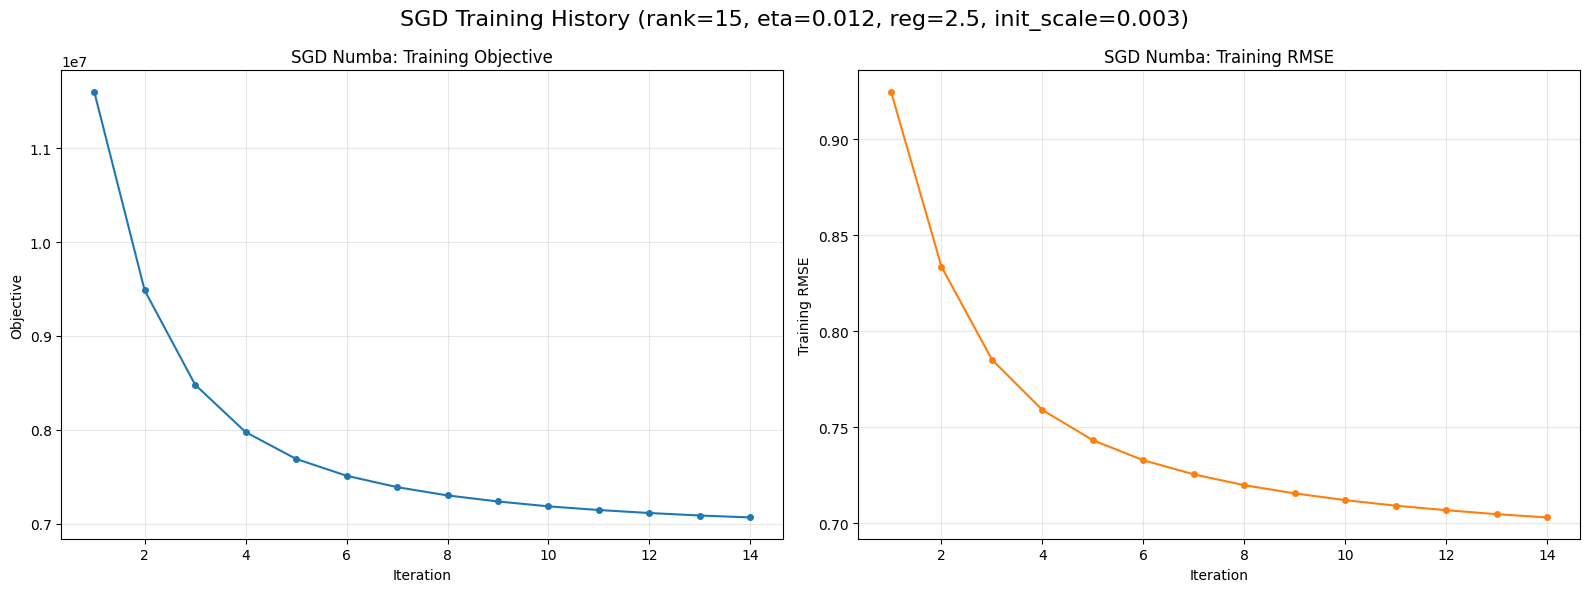

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fig.suptitle(
    "SGD Training History "
    f"(rank={best_sgd_rank}, eta={best_sgd_eta}, "
    f"reg={best_sgd_reg}, init_scale={best_sgd_init_scale})",
    fontsize=16,
)

axes[0].plot(
    sgd_history["iteration"],
    sgd_history["objective"],
    marker="o",
    markersize=4,
)

axes[0].set_title("SGD Numba: Training Objective")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Objective")
axes[0].grid(alpha=0.3)

axes[1].plot(
    sgd_history["iteration"],
    sgd_history["train_rmse"],
    marker="o",
    markersize=4,
    color="tab:orange",
)

axes[1].set_title("SGD Numba: Training RMSE")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Training RMSE")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Models

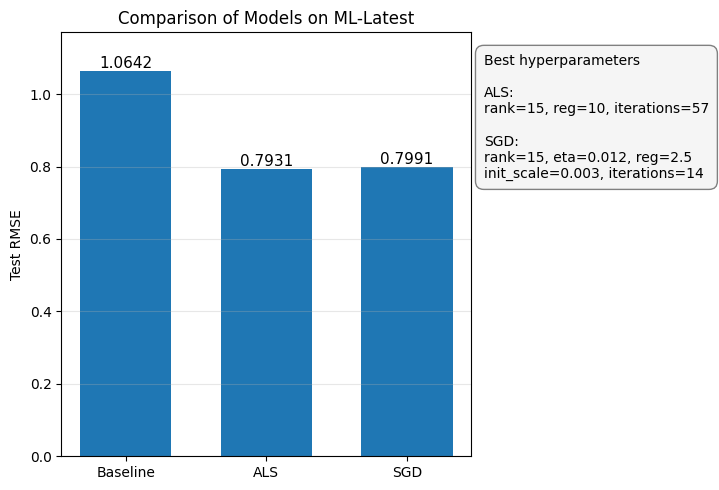

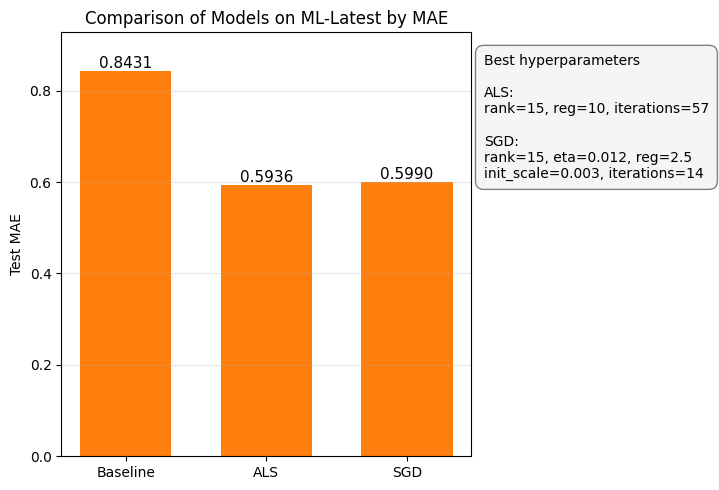

In [12]:
model_names = [
    "Baseline",
    "ALS",
    "SGD",
]

test_rmse_values = [
    baseline_test_rmse,
    als_test_rmse,
    sgd_test_rmse,
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    model_names,
    test_rmse_values,
    color="tab:blue",
    width=0.65,
)

ax.set_ylabel("Test RMSE")
ax.set_title("Comparison of Models on ML-Latest")
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(0, max(test_rmse_values) * 1.1)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom",
        fontsize=11,
    )

parameters_text = (
    "Best hyperparameters\n\n"
    f"ALS:\n"
    f"rank={best_als_rank}, reg={best_als_reg}, "
    f"iterations={best_als_n_iter}\n\n"
    f"SGD:\n"
    f"rank={best_sgd_rank}, eta={best_sgd_eta}, "
    f"reg={best_sgd_reg}\n"
    f"init_scale={best_sgd_init_scale}, "
    f"iterations={best_sgd_n_iter}"
)

ax.text(
    1.03,
    0.95,
    parameters_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    bbox={
        "boxstyle": "round,pad=0.6",
        "facecolor": "whitesmoke",
        "edgecolor": "gray",
    },
)

plt.tight_layout(rect=[0, 0, 0.74, 1])
plt.show()

test_mae_values = [
    baseline_test_mae,
    als_test_mae,
    sgd_test_mae,
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    model_names,
    test_mae_values,
    color="tab:orange",
    width=0.65,
)

ax.set_ylabel("Test MAE")
ax.set_title("Comparison of Models on ML-Latest by MAE")
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(0, max(test_mae_values) * 1.1)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom",
        fontsize=11,
    )

ax.text(
    1.03,
    0.95,
    parameters_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    bbox={
        "boxstyle": "round,pad=0.6",
        "facecolor": "whitesmoke",
        "edgecolor": "gray",
    },
)

plt.tight_layout(rect=[0, 0, 0.74, 1])
plt.show()